In [68]:
#25 입력받아 , 산점도 그래프에 표시하고 곡선도 출력

In [69]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler  # 정규화클래스
from sklearn.model_selection import train_test_split

In [70]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 
    1000.0, 1000.0]
    )

In [71]:
#학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [72]:
train_data=train_data.reshape(-1,1)
train_data
test_data=test_data.reshape(-1,1)
test_data[:2]

array([[44. ],
       [36.5]])

In [73]:
#데이터 전처리- 다항회귀
train_poly =np.column_stack((train_data**2,train_data))
test_poly=np.column_stack((test_data**2,test_data))
train_poly[:2]
test_poly[:2]

array([[1936.  ,   44.  ],
       [1332.25,   36.5 ]])

In [74]:
#데이터 학습
lr= LinearRegression()
lr.fit(train_poly,train_label)

#데이터예측
predict = lr.predict(test_poly)
print("무게예측:",predict)

#정확도
score=lr.score(train_poly,train_label)
score2=lr.score(test_poly,test_label)
print("train정확도:",score)
print("test정확도:",score2)

무게예측: [1121.66016405  673.02849647  133.88934062  809.71128059  133.88934062
  287.46042365   86.38422857  867.98550366  867.98550366   39.37499919
  118.80930574  157.18135789  287.46042365  182.53115197]
train정확도: 0.9726084210794236
test정확도: 0.9723775504631424


In [75]:
in_data =25
result = lr.predict([[in_data**2,in_data]])
print("예측무게:",result)

예측무게: [209.93872286]


In [76]:
#point
point = np.arange(15,50)
print(lr.coef_,lr.intercept_)

[  1.02888841 -23.007961  ] 142.08249407882747


# 다항회귀로 산점도 그래프 그리기
- 예측 무게 = a × 길이² + b × 길이 + c

#point: 길이들

#lr.coef_[0] : 제곱 항에 곱하는 값 a

#lr.coef_[1] : 길이에 곱하는 값 b

#lr.intercept : 마지막에 더하는 값 c 

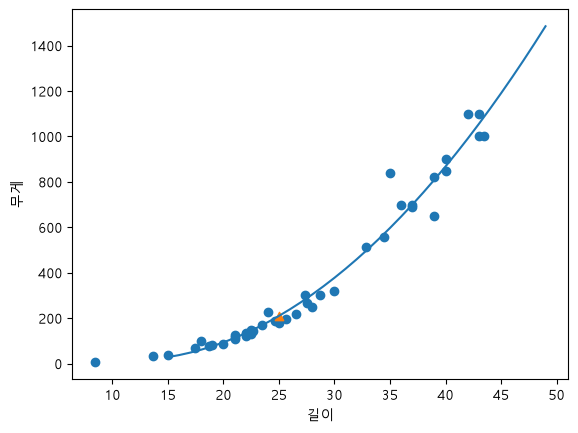

In [77]:
#산점도 그래프
plt.scatter(train_data,train_label)
plt.scatter(in_data,result[0],marker="^")

plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()